### 1. Objetivo y alcance

##### Target Analysis

Definir los objetivos de regresión y clasificación, y la unidad
de análisis para clustering.

Alcance: partición `train` de `config.py`, 2024-10-01 a 2026-02-22
(510 días). No se cargan validación ni test.

Alcance histórico: la primera exploración usó junio–septiembre de 2026,
periodo que ahora pertenece a test. Sus resultados no se reutilizan.

In [1]:
from mibici.dataset import get_split_periods
from mibici.pipeline import load_stage
import pandas as pd

data = load_stage("quality_fixes")  # partición train por defecto

trips = data["viajes"].copy()
stations = data["estaciones"].copy()

# Límites de train: inicio incluido, fin excluido
train_start, train_end = get_split_periods()["train"]
train_days = pd.date_range(train_start, train_end - pd.Timedelta(days=1), freq="D")
print(f"Train: {train_days[0].date()} a {train_days[-1].date()} ({len(train_days)} días)")

2026-10-18 08:56:00.911 | INFO     | mibici.config:<module>:11 - PROJ_ROOT path is: X:\Repositorios\Personal\Kaggle\notebooks\mibici\mibici_predictions


2026-10-18 08:56:08.646 | INFO     | mibici.dataset:load_raw:166 - Partición train: 2024-10-01 a 2026-02-22
2026-10-18 08:56:08.651 | INFO     | mibici.dataset:load_raw:170 - Viajes cargados: 6,311,111


Train: 2024-10-01 a 2026-02-22 (510 días)


### P1 — Regression

- Unidad: estación y día.
- Objetivo: cantidad de salidas registradas.
- Horizonte propuesto: predecir el día siguiente.
- Pendiente: decidir el tratamiento de viajes con duración cero.

In [2]:
daily_departures = (
    trips.assign(date=trips["Inicio_del_viaje"].dt.normalize())
    .groupby(["Origen_Id", "date"])
    .size()
    .rename("departures")
    .reset_index()
)

display(daily_departures.head())
display(daily_departures["departures"].describe())

,Origen_Id,date,departures
0,2,2024-10-01,21
1,2,2024-10-02,74
2,2,2024-10-03,83
3,2,2024-10-04,63
4,2,2024-10-05,44


count    186198.000000
mean         33.894623
std          34.345279
min           1.000000
25%          11.000000
50%          23.000000
75%          46.000000
max         561.000000
Name: departures, dtype: float64

In [3]:
#continuidad temporal de cada estación

print(f"Primera fecha: {daily_departures['date'].min()}")
print(f"Última fecha: {daily_departures['date'].max()}")

station_coverage = (
    daily_departures.groupby("Origen_Id")
    .agg(
        days_with_departures=("date", "nunique"),
        total_departures=("departures", "sum"),
    )
)

display(station_coverage["days_with_departures"].describe())
display(station_coverage.sort_values("days_with_departures").head(10))

Primera fecha: 2024-10-01 00:00:00
Última fecha: 2026-02-22 00:00:00


count    371.000000
mean     501.881402
std       42.301453
min       80.000000
25%      509.000000
50%      510.000000
75%      510.000000
max      510.000000
Name: days_with_departures, dtype: float64

,days_with_departures,total_departures
Origen_Id,,
402,80,493
180,120,5712
401,134,665
240,240,909
400,259,8817
20,389,20723
391,418,1847
398,432,5662
397,432,5940


In [4]:
station_coverage = (
    daily_departures.groupby("Origen_Id")
    .agg(
        first_departure_date=("date", "min"),
        last_departure_date=("date", "max"),
        days_with_departures=("date", "nunique"),
        total_departures=("departures", "sum"),
    )
)

display(
    station_coverage
    .sort_values("days_with_departures")
    .head(10)
)

,first_departure_date,last_departure_date,days_with_departures,total_departures
Origen_Id,,,,
402,2025-12-05,2026-02-22,80,493
180,2024-10-01,2025-01-28,120,5712
401,2025-10-09,2026-02-22,134,665
240,2024-10-01,2025-06-06,240,909
400,2025-06-09,2026-02-22,259,8817
20,2024-10-01,2025-10-24,389,20723
391,2024-12-16,2026-02-21,418,1847
398,2024-12-18,2026-02-22,432,5662
397,2024-12-18,2026-02-22,432,5940


In [5]:
station_coverage["days_in_span"] = (
    station_coverage["last_departure_date"]
    - station_coverage["first_departure_date"]
).dt.days + 1

station_coverage["days_without_departures_in_span"] = (
    station_coverage["days_in_span"]
    - station_coverage["days_with_departures"]
)

display(
    station_coverage
    .sort_values("days_with_departures")
    .head(10)
)

,first_departure_date,last_departure_date,days_with_departures,total_departures,days_in_span,days_without_departures_in_span
Origen_Id,,,,,,
402,2025-12-05,2026-02-22,80,493,80,0
180,2024-10-01,2025-01-28,120,5712,120,0
401,2025-10-09,2026-02-22,134,665,137,3
240,2024-10-01,2025-06-06,240,909,249,9
400,2025-06-09,2026-02-22,259,8817,259,0
20,2024-10-01,2025-10-24,389,20723,389,0
391,2024-12-16,2026-02-21,418,1847,433,15
398,2024-12-18,2026-02-22,432,5662,432,0
397,2024-12-18,2026-02-22,432,5940,432,0


In [6]:
station_coverage = (
    daily_departures.groupby("Origen_Id")
    .agg(
        first_departure_date=("date", "min"),
        last_departure_date=("date", "max"),
        days_with_departures=("date", "nunique"),
        total_departures=("departures", "sum"),
    )
)

station_coverage["days_in_span"] = (
    station_coverage["last_departure_date"]
    - station_coverage["first_departure_date"]
).dt.days + 1

station_coverage["days_without_departures_in_span"] = (
    station_coverage["days_in_span"]
    - station_coverage["days_with_departures"]
)

station_coverage["station_name"] = station_coverage.index.map(
    stations.set_index("id")["name"]
)


print(f"Desde: {daily_departures['date'].min()}")
print(f"Hasta: {daily_departures['date'].max()}")

display(
    station_coverage
    .sort_values("days_with_departures")
    .head(15)
)


Desde: 2024-10-01 00:00:00
Hasta: 2026-02-22 00:00:00


,first_departure_date,last_departure_date,days_with_departures,total_departures,days_in_span,days_without_departures_in_span,station_name
Origen_Id,,,,,,,
402,2025-12-05,2026-02-22,80,493,80,0,(ZPN-080) Av. Moctezuma / Av. Netzahualcóyotl
180,2024-10-01,2025-01-28,120,5712,120,0,(GDL-113) C. Ghilardi / C. Arista
401,2025-10-09,2026-02-22,134,665,137,3,(ZPN-079) Av. Coyoacan / C. Chimalpopoca
240,2024-10-01,2025-06-06,240,909,249,9,ex-(GDL-173) C. Caballerango / C. Caporales
400,2025-06-09,2026-02-22,259,8817,259,0,(GDL-173) Av. 5 de Febrero / Av. Dr. R Michel
20,2024-10-01,2025-10-24,389,20723,389,0,(GDL-018) Av. México / C. Manuel M. Diéguez
391,2024-12-16,2026-02-21,418,1847,433,15,(ZPN-078) Lago Constanza / San Jorge
398,2024-12-18,2026-02-22,432,5662,432,0,(GDL-281) Nevado Toluca / Av de los Maestros
397,2024-12-18,2026-02-22,432,5940,432,0,(GDL-279) Belen / Av. de los Maestros


In [7]:
daily_arrivals = (
    trips.assign(date=trips["Fin_del_viaje"].dt.normalize())
    .groupby(["Destino_Id", "date"])
    .size()
    .rename("arrivals")
    .reset_index()
    .rename(columns={"Destino_Id": "station_id"})
)

In [8]:

selected_stations = (
    station_coverage
    .sort_values("days_with_departures")
    .head(10)
    .index
)

calendar = pd.MultiIndex.from_product(
    [
        selected_stations,
        train_days,
    ],
    names=["station_id", "date"],
)

station_daily_activity = (
    daily_departures
    .rename(columns={"Origen_Id": "station_id"})
    .set_index(["station_id", "date"])[["departures"]]
    .join(
        daily_arrivals.set_index(["station_id", "date"]),
        how="outer",
    )
    .reindex(calendar)
    .fillna(0)
    .astype("int64")
    .reset_index()
)

In [9]:
active_days = station_daily_activity.loc[
    station_daily_activity["departures"].gt(0)
    | station_daily_activity["arrivals"].gt(0)
]

activity_span = active_days.groupby("station_id").agg(
    first_activity=("date", "min"),
    last_activity=("date", "max"),
    days_with_activity=("date", "nunique"),
)

activity_span["days_in_span"] = (
    activity_span["last_activity"]
    - activity_span["first_activity"]
).dt.days + 1

activity_span["no_activity_inside_span"] = (
    activity_span["days_in_span"]
    - activity_span["days_with_activity"]
)

display(activity_span)

,first_activity,last_activity,days_with_activity,days_in_span,no_activity_inside_span
station_id,,,,,
20,2024-10-01,2025-10-24,389,389,0
180,2024-10-01,2025-01-28,120,120,0
240,2024-10-01,2025-06-06,248,249,1
391,2024-12-16,2026-02-22,433,434,1
394,2024-12-17,2026-02-22,433,433,0
397,2024-12-18,2026-02-22,432,432,0
398,2024-12-18,2026-02-22,432,432,0
400,2025-06-09,2026-02-22,259,259,0
401,2025-10-09,2026-02-22,135,137,2


In [10]:
activity_check = station_daily_activity.merge(
    activity_span[["first_activity", "last_activity"]],
    left_on="station_id",
    right_index=True,
    how="left",
)

internal_gaps = activity_check.loc[
    activity_check["date"].between(
        activity_check["first_activity"],
        activity_check["last_activity"],
    )
    & activity_check["departures"].eq(0)
    & activity_check["arrivals"].eq(0),
    ["station_id", "date"],
]

display(internal_gaps)

,station_id,date
1508,401,2026-02-01
1509,401,2026-02-02
1742,240,2025-05-01
3510,391,2025-12-25


In [11]:
network_departures = (
    trips.groupby(trips["Inicio_del_viaje"].dt.normalize())
    .size()
    .rename("network_departures")
)

gap_review = internal_gaps.copy()
gap_review["network_departures"] = (
    gap_review["date"].map(network_departures).fillna(0).astype("int64")
)

display(gap_review)

,station_id,date,network_departures
1508,401,2026-02-01,8686
1509,401,2026-02-02,8267
1742,240,2025-05-01,8256
3510,391,2025-12-25,3113


In [12]:
#Ampliamos la seleccion a analizar
station_ids = pd.Index(
    pd.concat([
        trips["Origen_Id"],
        trips["Destino_Id"],
    ]).unique(),
    name="station_id",
)

calendar = pd.MultiIndex.from_product(
    [
        station_ids,
        train_days,
    ],
    names=["station_id", "date"],
)

station_daily_activity = (
    daily_departures
    .rename(columns={"Origen_Id": "station_id"})
    .set_index(["station_id", "date"])[["departures"]]
    .join(
        daily_arrivals.set_index(["station_id", "date"]),
        how="outer",
    )
    .reindex(calendar)
    .fillna(0)
    .astype("int64")
    .reset_index()
)

In [13]:
has_activity = (
    station_daily_activity["departures"].gt(0)
    | station_daily_activity["arrivals"].gt(0)
)

activity_span = (
    station_daily_activity.loc[has_activity]
    .groupby("station_id")
    .agg(
        first_activity=("date", "min"),
        last_activity=("date", "max"),
        days_with_activity=("date", "nunique"),
    )
)

activity_span["days_in_span"] = (
    activity_span["last_activity"]
    - activity_span["first_activity"]
).dt.days + 1

activity_span["no_activity_inside_span"] = (
    activity_span["days_in_span"]
    - activity_span["days_with_activity"]
)

print(f"Estaciones revisadas: {len(activity_span):,}")
print(
    "Estaciones con huecos internos:",
    activity_span["no_activity_inside_span"].gt(0).sum(),
)

display(
    activity_span
    .sort_values("no_activity_inside_span", ascending=False)
    .head(15)
)

Estaciones revisadas: 371
Estaciones con huecos internos: 67


,first_activity,last_activity,days_with_activity,days_in_span,no_activity_inside_span
station_id,,,,,
302,2024-10-01,2026-02-22,467,510,43
356,2024-10-01,2026-02-22,480,510,30
19,2024-10-01,2026-02-22,485,510,25
21,2024-10-01,2026-02-22,494,510,16
224,2024-10-01,2026-02-22,498,510,12
146,2024-10-01,2026-02-22,500,510,10
101,2024-10-01,2026-02-22,501,510,9
380,2024-10-01,2026-02-22,502,510,8
287,2024-10-01,2026-02-22,503,510,7


In [14]:
activity_check = station_daily_activity.merge(
    activity_span[["first_activity", "last_activity"]],
    left_on="station_id",
    right_index=True,
    how="left",
)

internal_gaps = activity_check.loc[
    activity_check["date"].between(
        activity_check["first_activity"],
        activity_check["last_activity"],
    )
    & activity_check["departures"].eq(0)
    & activity_check["arrivals"].eq(0)
]

gap_dates = (
    internal_gaps.groupby("date")["station_id"]
    .nunique()
    .rename("stations_without_activity")
    .to_frame()
)

gap_dates["network_departures"] = (
    gap_dates.index.to_series()
    .map(network_departures)
    .fillna(0)
    .astype("int64")
)

display(
    gap_dates.sort_values(
        "stations_without_activity",
        ascending=False,
    ).head(15)
)

,stations_without_activity,network_departures
date,,
2024-12-25,14,2782
2025-12-25,11,3113
2025-02-16,8,9224
2025-02-15,7,10026
2025-02-13,7,15281
2026-01-01,7,3616
2025-02-14,7,14686
2024-10-27,6,8400
2024-10-28,4,14729


In [15]:
# Comprobaciones: tablas no vacías y fechas dentro de train
def assert_in_train(dates, name):
    assert dates.ge(train_start).all() and dates.lt(train_end).all(), name

assert not daily_departures.empty and not station_daily_activity.empty
assert not activity_span.empty and not internal_gaps.empty and not gap_dates.empty

assert_in_train(daily_departures["date"], "daily_departures")
assert_in_train(station_daily_activity["date"], "station_daily_activity")
assert_in_train(activity_span["first_activity"], "first_activity")
assert_in_train(activity_span["last_activity"], "last_activity")
assert_in_train(internal_gaps["date"], "internal_gaps")
assert_in_train(gap_dates.index.to_series(), "gap_dates")

print(f"station_daily_activity: {len(station_daily_activity):,} filas, "
      f"{station_daily_activity['date'].min().date()} a {station_daily_activity['date'].max().date()}")
print(f"Huecos internos: {len(internal_gaps):,} estación-días en {internal_gaps['station_id'].nunique()} estaciones")

station_daily_activity: 189,210 filas, 2024-10-01 a 2026-02-22
Huecos internos: 294 estación-días en 67 estaciones


In [16]:

#Comprobando que se haya aplicado la corrección de continuidad temporal y conservación del total de salidas

from mibici.modeling.p1 import load_p1_data

daily_demand = load_p1_data()

display(daily_demand.head())

2026-10-18 08:56:26.499 | INFO     | mibici.dataset:load_raw:166 - Partición train: 2024-10-01 a 2026-02-22
2026-10-18 08:56:26.499 | INFO     | mibici.dataset:load_raw:170 - Viajes cargados: 6,311,111


,station_id,date,departures
0,2,2024-10-01,21
1,2,2024-10-02,74
2,2,2024-10-03,83
3,2,2024-10-04,63
4,2,2024-10-05,44


In [17]:
assert daily_demand["departures"].sum() == len(trips)
assert not daily_demand.duplicated(["station_id", "date"]).any()

date_steps = (
    daily_demand.sort_values(["station_id", "date"])
    .groupby("station_id")["date"]
    .diff()
    .dropna()
)

assert date_steps.eq(pd.Timedelta(days=1)).all()

assert_in_train(daily_demand["date"], "daily_demand")
print(f"daily_demand: {len(daily_demand):,} estación-días, "
      f"{daily_demand['station_id'].nunique()} estaciones, "
      f"{daily_demand['date'].min().date()} a {daily_demand['date'].max().date()}")

daily_demand: 186,753 estación-días, 371 estaciones, 2024-10-01 a 2026-02-22


In [18]:
#DISTRIBUCION DE LA VARIABLE TARGET
display(daily_demand["departures"].describe())

print(
    f"Estación-días con cero salidas: "
    f"{daily_demand['departures'].eq(0).mean():.2%}"
)

count    186753.000000
mean         33.793894
std          34.343801
min           0.000000
25%          11.000000
50%          23.000000
75%          46.000000
max         561.000000
Name: departures, dtype: float64

Estación-días con cero salidas: 0.30%


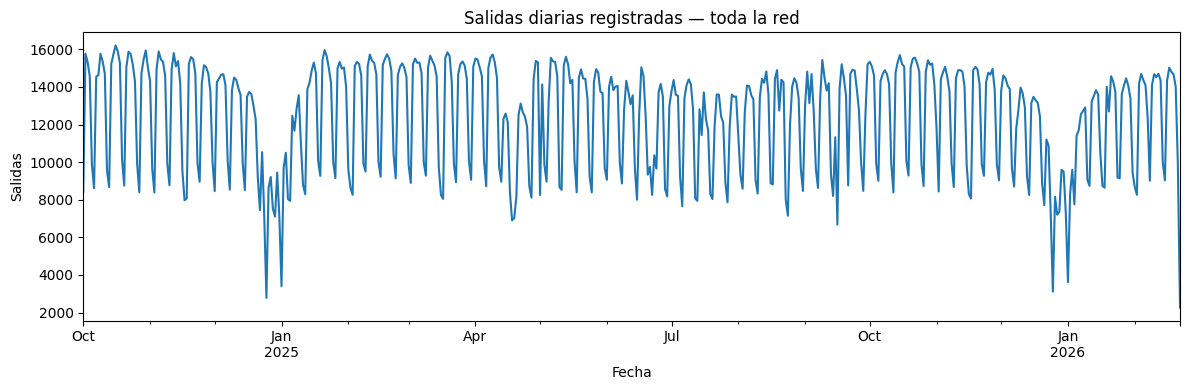

In [19]:
import matplotlib.pyplot as plt

network_daily_departures = (
    daily_demand.groupby("date")["departures"].sum().sort_index()
)

network_daily_departures.plot(
    figsize=(12, 4),
    title="Salidas diarias registradas — toda la red",
    xlabel="Fecha",
    ylabel="Salidas",
)

plt.tight_layout()
plt.show()

In [20]:
weekday_summary = (
    network_daily_departures
    .groupby(network_daily_departures.index.dayofweek)
    .agg(["mean", "median", "count"])
    .reindex(range(7))
)

weekday_summary.index = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo",
]

display(weekday_summary.round(2))

,mean,median,count
Lunes,13214.58,13855.5,72
Martes,14037.63,14772.0,73
Miércoles,14135.22,14695.0,73
Jueves,13850.10,14672.0,73
Viernes,13378.07,14019.0,73
Sábado,9577.92,9748.0,73
Domingo,8441.08,8591.0,73


In [21]:
daily_network_summary = (
    daily_demand.groupby("date")
    .agg(
        total_departures=("departures", "sum"),
        stations_with_departures=(
            "departures",
            lambda values: values.gt(0).sum(),
        ),
    )
)

daily_network_summary["departures_per_station_with_departures"] = (
    daily_network_summary["total_departures"]
    / daily_network_summary["stations_with_departures"]
)

display(
    daily_network_summary.resample("MS").mean().round(2)
)

,total_departures,stations_with_departures,departures_per_station_with_departures
date,,,
2024-10-01,13506.13,358.84,37.62
2024-11-01,13036.30,358.73,36.33
2024-12-01,10969.32,362.29,30.27
2025-01-01,12264.00,366.87,33.39
2025-02-01,13304.61,365.36,36.40
2025-03-01,13068.06,366.29,35.66
2025-04-01,12206.43,366.37,33.30
2025-05-01,12770.68,366.65,34.82
2025-06-01,11887.03,365.93,32.47


Las salidas diarias promedio de la red son menores en diciembre
(10,969 en 2024 y 10,820 en 2025) y mayores en octubre (13,506 en 2024
y 13,550 en 2025). Las estaciones con salidas pasan de unas 359 por día
en octubre–noviembre de 2024 a entre 362 y 367 desde diciembre de 2024.
La causa de estas variaciones no está confirmada.

In [22]:
station_target_summary = (
    daily_demand.groupby("station_id")["departures"]
    .agg(["mean", "median", "max", "count"])
    .rename(columns={"count": "observed_span_days"})
    .sort_values("mean", ascending=False)
)

display(station_target_summary.head(10))
display(station_target_summary.tail(10))

,mean,median,max,observed_span_days
station_id,,,,
51,237.919608,247.0,351,510
35,213.486275,224.0,362,510
271,186.907843,203.0,289,510
11,183.235294,199.0,277,510
52,173.801961,186.0,263,510
50,155.676471,152.5,418,510
54,143.719608,147.0,330,510
194,117.100394,107.5,561,508
260,107.519608,113.0,206,510


,mean,median,max,observed_span_days
station_id,,,,
153,4.952941,5.0,13,510
101,4.860784,4.5,17,510
362,4.858824,5.0,17,510
401,4.854015,5.0,13,137
318,4.471513,4.0,13,509
391,4.255760,4.0,15,434
380,3.864706,4.0,12,510
146,3.743137,4.0,13,510
240,3.650602,4.0,9,249


#### Conclusión sobre la cobertura temporal

Se analizaron las 371 estaciones con actividad en train
(2024-10-01 a 2026-02-22). De ellas, 67 presentan días sin salidas
ni llegadas dentro de su tramo de actividad observado:
294 estación-días en total.

Las fechas con más estaciones sin actividad son el 25 de diciembre
(14 estaciones en 2024 y 11 en 2025) y el 1 de enero de 2026 (7),
días de baja actividad de la red, aunque con más de 2,700 salidas.
Del 13 al 16 de febrero de 2025 hubo entre 7 y 8 estaciones sin actividad
con más de 9,000 salidas diarias en la red. No se identificó una ausencia
total de registros de la red, aunque esto no garantiza la integridad
de los archivos.

Algunos tramos de actividad no cubren todo train: la estación 180 termina
el 2025-01-28, la 240 (`ex-(GDL-173)`) el 2025-06-06 y la 20 el 2025-10-24;
la 400 (`(GDL-173)`) empieza el 2025-06-09 y la 402 el 2025-12-05.

Para la tabla exploratoria se completan con cero las salidas
ausentes dentro del tramo de actividad observado de cada estación.
No se extiende automáticamente ese tramo hacia fechas anteriores
o posteriores. Estos ceros representan salidas registradas,
sin atribuir su causa a falta de demanda o cierre.

La implementación está en `build_daily_departures` de `modeling/p1.py`
(H-co-010). El calendario de evaluación se definirá sin utilizar
actividad futura.

#### Estaciones 240 y 400

Comparación descriptiva. No se unen ni se cambian sus IDs.
El catálogo corresponde a septiembre de 2026.

In [23]:
import numpy as np

pair = [240, 400]

catalog_pair = stations.set_index("id").loc[pair, ["name", "latitude", "longitude", "dpcapacity"]]

activity_pair = pd.DataFrame({
    "first_departure": trips.loc[trips["Origen_Id"].isin(pair)].groupby("Origen_Id")["Inicio_del_viaje"].min(),
    "last_departure": trips.loc[trips["Origen_Id"].isin(pair)].groupby("Origen_Id")["Inicio_del_viaje"].max(),
    "first_arrival": trips.loc[trips["Destino_Id"].isin(pair)].groupby("Destino_Id")["Fin_del_viaje"].min(),
    "last_arrival": trips.loc[trips["Destino_Id"].isin(pair)].groupby("Destino_Id")["Fin_del_viaje"].max(),
    "departures": trips["Origen_Id"].value_counts().reindex(pair),
    "arrivals": trips["Destino_Id"].value_counts().reindex(pair),
})

display(catalog_pair.join(activity_pair).T)

# Distancia aproximada entre coordenadas del catálogo (haversine)
lat1, lon1, lat2, lon2 = np.radians(
    catalog_pair[["latitude", "longitude"]].to_numpy().ravel()
)
distance_m = 2 * 6_371_000 * np.arcsin(np.sqrt(
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
))
print(f"Distancia entre coordenadas del catálogo: {distance_m:,.0f} m")

# ¿Hubo días con actividad en ambas estaciones?
pair_days = station_daily_activity.loc[
    station_daily_activity["station_id"].isin(pair)
    & (station_daily_activity["departures"].gt(0) | station_daily_activity["arrivals"].gt(0))
]
both_active = pair_days.groupby("date")["station_id"].nunique().eq(2)
print(f"Días con actividad en ambas: {both_active.sum()}")
between = (
    (trips["Origen_Id"].eq(240) & trips["Destino_Id"].eq(400))
    | (trips["Origen_Id"].eq(400) & trips["Destino_Id"].eq(240))
)
print(f"Viajes entre 240 y 400 (en cualquier sentido): {between.sum()}")

id,240,400
name,ex-(GDL-173) C. Caballerango / C. Caporales,(GDL-173) Av. 5 de Febrero / Av. Dr. R Michel
latitude,20.64504,20.661973
longitude,-103.30518,-103.346019
dpcapacity,19,19
first_departure,2024-10-01 14:04:00,2025-06-09 18:23:16
last_departure,2025-06-06 09:52:00,2026-02-22 10:15:10
first_arrival,2024-10-01 14:15:00,2025-06-09 18:57:15
last_arrival,2025-06-05 23:14:14,2026-02-22 10:14:53
departures,909,8817
arrivals,604,10013


Distancia entre coordenadas del catálogo: 4,648 m
Días con actividad en ambas: 0
Viajes entre 240 y 400 (en cualquier sentido): 0


Diferencias observadas en train (sin unir las estaciones):

- Ambas tienen el código `GDL-173` y capacidad 19 en el catálogo.
- Nombre: 240 tiene prefijo `ex-` y está en C. Caballerango / C. Caporales;
  400 está en Av. 5 de Febrero / Av. Dr. R Michel.
- Coordenadas: separadas unos 4,648 m según el catálogo.
- Actividad de 240: primera salida 2024-10-01 14:04, última salida
  2025-06-06 09:52 y última llegada 2025-06-05 23:14:14
  (909 salidas y 604 llegadas).
- Actividad de 400: primera salida 2025-06-09 18:23:16 y última salida
  2026-02-22 10:15:10 (8,817 salidas y 10,013 llegadas).
- No hay días con actividad en ambas ni viajes entre ellas.

Comparten código, pero el catálogo las ubica en sitios distintos.
La decisión de unirlas queda pendiente (H-co-012); no se modifican sus IDs.

#### Calendario de modelado

`build_training_daily_data` (modeling/p1.py) crea filas desde la primera
actividad de cada estación hasta el corte de train. Se compara con el último
día de actividad observado en train.

In [24]:
from mibici.modeling.p1 import build_training_daily_data

model_daily = build_training_daily_data(trips, start=train_start, end_exclusive=train_end)
assert_in_train(model_daily["date"], "model_daily")

last_train_day = train_days[-1]
model_last = model_daily.groupby("station_id")["date"].max()
print(f"Estaciones con filas hasta el último día de train: "
      f"{model_last.eq(last_train_day).sum()} de {model_last.size}")

after_last = model_daily.merge(
    activity_span["last_activity"], left_on="station_id", right_index=True
)
after_last = after_last.loc[after_last["date"].gt(after_last["last_activity"])]
assert after_last["departures"].eq(0).all()

prolonged = (
    activity_span.loc[activity_span["last_activity"].lt(last_train_day), ["first_activity", "last_activity"]]
    .assign(
        days_until_cut=lambda d: (last_train_day - d["last_activity"]).dt.days,
        zero_rows_after_last=after_last.groupby("station_id").size(),
    )
    .sort_values("days_until_cut", ascending=False)
)
prolonged["station_name"] = prolonged.index.map(stations.set_index("id")["name"])

print(f"Filas posteriores a la última actividad: {len(after_last):,}")
display(prolonged)

Estaciones con filas hasta el último día de train: 371 de 371
Filas posteriores a la última actividad: 788


,first_activity,last_activity,days_until_cut,zero_rows_after_last,station_name
station_id,,,,,
180,2024-10-01,2025-01-28,390,390,(GDL-113) C. Ghilardi / C. Arista
240,2024-10-01,2025-06-06,261,261,ex-(GDL-173) C. Caballerango / C. Caporales
20,2024-10-01,2025-10-24,121,121,(GDL-018) Av. México / C. Manuel M. Diéguez
194,2024-10-01,2026-02-20,2,2,(GDL-127) Av. Vallarta / Av. de Los Arcos
95,2024-10-01,2026-02-21,1,1,(ZPN-005) C. Del Corral / C. Anáhuac
103,2024-10-01,2026-02-21,1,1,(ZPN-013) C. Eva Briseño / C. Javier Mina
127,2024-10-01,2026-02-21,1,1,(ZPN-033) Av Lázaro Cárdenas / Av San Ignacio
120,2024-10-01,2026-02-21,1,1,(ZPN-030) Av.Juan Pablo II / Lázaro Cárdenas
152,2024-10-01,2026-02-21,1,1,(TLQ-011) C. Jalisco / C. Hidalgo


El calendario de modelado prolonga las 371 estaciones hasta el último
día de train (2026-02-22). Para las 18 estaciones cuya última actividad es
anterior, agrega 788 filas con cero salidas después de esa actividad.

Tres estaciones dejaron de tener actividad mucho antes del corte:
- 180: última actividad 2025-01-28 (390 días antes).
- 240: última actividad 2025-06-06 (261 días antes).
- 20: última actividad 2025-10-24 (121 días antes).

Las otras 15 terminan uno o dos días antes del corte.
Su elegibilidad para modelado debe revisarse usando únicamente
información anterior a validación (H-co-010).

#### Conclusiones de P1

El objetivo propuesto es predecir salidas registradas por estación
y día, con horizonte de un día.

Se identificaron diferencias importantes entre estaciones,
menor actividad de la red durante fines de semana y en diciembre.

Se completó el calendario exploratorio con ceros dentro del tramo
de actividad observado: 186,753 estación-días de 371 estaciones,
0.30 % con cero salidas, conservando el total de salidas.

Para modelado se deberá definir el corte temporal, las estaciones
elegibles usando información disponible al predecir y el tratamiento
de viajes con duración cero. Se evaluará el desempeño por estación
y nivel de actividad, además del resultado global.

### P2 — Classification

No contamos con inventario observado de bicicletas ni anclajes libres.

Se debe definir un proxy de riesgo basado en flujos de viajes y
capacidad. No se interpretará como disponibilidad real.

Pendiente: definir fórmula, umbral, horizonte y momento de predicción.
Revisar las estaciones con capacidad cero antes de construir el proxy.

### P3 — Clustering

- Unidad: estación.
- No existe una variable objetivo supervisada.
- Se explorarán perfiles horarios, diferencias entre días laborales
  y fines de semana, y ubicación.
- Pendiente: definir periodo, estaciones elegibles y variables.